# Dataset analysis

Run these cells to summarize what is in the current training and finetuning data: source sizes, labels, mechanism classes, duplicate fingerprints, and fingerprint feature families.


In [9]:
import json
import os
import pickle
import sys
from collections import Counter

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from shared.ml_helper import make_fingerprint
from shared.fingerprint_schema import build_feature_entries, build_section_layout, fingerprint_size


In [10]:
dataset_dirs = [
    ("base", "training_sets/20260202"),
    ("finetuning", "finetuning_combined"),
]

mechanism_type_names = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: "-H+ to bond",
    9: "-H+ to atom",
    10: "elimination to bond",
}

expected_fingerprint_size = fingerprint_size()
print(f"Expected fingerprint width: {expected_fingerprint_size}")


Expected fingerprint width: 182


In [11]:
def natural_sort_key(value):
    text = str(value)
    return (not text.isdigit(), int(text) if text.isdigit() else text)


def load_mechanism_records(dataset_name, dataset_dir):
    records = []
    skipped = Counter()

    if not os.path.isdir(dataset_dir):
        print(f"Skipping missing directory: {dataset_dir}")
        return records, skipped

    subdirs = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
    for subdir in sorted(subdirs, key=natural_sort_key):
        folder_path = os.path.join(dataset_dir, subdir)
        json_path = os.path.join(folder_path, 'data.json')
        pkl_path = os.path.join(folder_path, 'sm.pkl')

        if not os.path.exists(json_path) or not os.path.exists(pkl_path):
            skipped['missing_files'] += 1
            continue

        try:
            with open(pkl_path, 'rb') as f:
                sm = pickle.load(f)
            with open(json_path, 'r') as f:
                data = json.load(f)
        except Exception as e:
            skipped[f'load_error: {type(e).__name__}'] += 1
            continue

        contributor = data.get('contributor') or None
        for choice_id, info in data.get('choices', {}).items():
            outcome = info.get('probable')
            mechanism = info.get('mechanism')
            if outcome is None:
                skipped['unlabeled_choice'] += 1
                continue
            if not mechanism:
                skipped['missing_mechanism'] += 1
                continue

            try:
                fingerprint = make_fingerprint(sm, mechanism)
            except Exception as e:
                skipped[f'fingerprint_error: {type(e).__name__}'] += 1
                continue

            records.append({
                'source': dataset_name,
                'dataset_dir': dataset_dir,
                'folder': subdir,
                'choice_id': choice_id,
                'contributor': contributor,
                'probable': int(outcome),
                'mechanism': mechanism,
                'mechanism_type': mechanism[0],
                'mechanism_type_name': mechanism_type_names.get(mechanism[0], f"unknown={mechanism[0]}"),
                'fingerprint': fingerprint,
            })

    return records, skipped


In [12]:
all_records = []
skip_summary = {}
for dataset_name, dataset_dir in dataset_dirs:
    records, skipped = load_mechanism_records(dataset_name, dataset_dir)
    all_records.extend(records)
    skip_summary[dataset_name] = skipped

records_df = pd.DataFrame(all_records)
if records_df.empty:
    raise ValueError("No labeled mechanism records found. Check dataset_dirs.")

fingerprints = np.asarray(records_df['fingerprint'].tolist(), dtype=float)
if fingerprints.shape[1] != expected_fingerprint_size:
    raise ValueError(f"Fingerprint width mismatch: got {fingerprints.shape[1]}, expected {expected_fingerprint_size}")

print(f"Loaded {len(records_df):,} labeled mechanism examples")
display(records_df[['source', 'folder', 'choice_id', 'probable', 'mechanism_type_name', 'contributor']].head())
print("Skipped choices/files:")
for source, skipped in skip_summary.items():
    print(source, dict(skipped))


Loaded 9,503 labeled mechanism examples


,source,folder,choice_id,probable,mechanism_type_name,contributor
0,base,1,0,1,atom to atom,Richard
1,base,1,1,1,-H+ to atom,Richard
2,base,2,0,0,-H+ to atom,Richard
3,base,2,1,1,atom to atom,Richard
4,base,2,2,0,-H+ to atom,Richard


Skipped choices/files:
base {'unlabeled_choice': 132}
finetuning {'unlabeled_choice': 11774}


In [13]:
source_summary = (
    records_df.groupby('source')
    .agg(
        examples=('probable', 'size'),
        positives=('probable', 'sum'),
        unique_folders=('folder', 'nunique'),
        contributors=('contributor', 'nunique'),
    )
)
source_summary['negatives'] = source_summary['examples'] - source_summary['positives']
source_summary['positive_rate'] = source_summary['positives'] / source_summary['examples']
display(source_summary)

label_summary = pd.crosstab(records_df['source'], records_df['probable'], margins=True)
label_summary = label_summary.rename(columns={0: 'negative', 1: 'positive'})
display(label_summary)

mechanism_summary = pd.crosstab(
    records_df['mechanism_type_name'],
    records_df['probable'],
    margins=True,
).rename(columns={0: 'negative', 1: 'positive'}).sort_values('All', ascending=False)
display(mechanism_summary)


,examples,positives,unique_folders,contributors,negatives,positive_rate
source,,,,,,
base,9355,1409,396,1,7946,0.150615
finetuning,148,63,70,5,85,0.425676


probable,negative,positive,All
source,,,
base,7946,1409,9355
finetuning,85,63,148
All,8031,1472,9503


probable,negative,positive,All
mechanism_type_name,,,
All,8031,1472,9503
-H+ to bond,2943,178,3121
atom to bond,2525,530,3055
bond to bond,1182,89,1271
atom to H+,432,344,776
elimination to bond,269,51,320
atom to atom,130,165,295
bond to H+,230,30,260
-H+ to atom,199,49,248


In [14]:
def stable_fingerprint_key(row):
    return tuple('nan' if pd.isna(value) else int(value) for value in row)

fingerprint_keys = [stable_fingerprint_key(row) for row in fingerprints]
labeled_keys = [(key, int(outcome)) for key, outcome in zip(fingerprint_keys, records_df['probable'])]
records_df = records_df.assign(
    fingerprint_key=fingerprint_keys,
    labeled_fingerprint_key=labeled_keys,
)

duplicate_group_sizes = records_df.groupby('labeled_fingerprint_key').size()
duplicate_groups = duplicate_group_sizes[duplicate_group_sizes > 1]

print(f"Unique fingerprints: {records_df['fingerprint_key'].nunique():,}")
print(f"Unique labeled fingerprints: {records_df['labeled_fingerprint_key'].nunique():,}")
print(f"Duplicate labeled-fingerprint groups: {len(duplicate_groups):,}")
print(f"Rows inside duplicate labeled-fingerprint groups: {int(duplicate_groups.sum()):,}")

cross_source_duplicates = (
    records_df.groupby('labeled_fingerprint_key')['source']
    .nunique()
    .loc[lambda s: s > 1]
)
print(f"Duplicate labeled fingerprints appearing in multiple sources: {len(cross_source_duplicates):,}")

if len(duplicate_groups):
    dup_examples = (
        records_df[records_df['labeled_fingerprint_key'].isin(duplicate_groups.index)]
        .groupby(['mechanism_type_name', 'probable', 'source'])
        .size()
        .rename('rows')
        .reset_index()
        .sort_values('rows', ascending=False)
    )
    display(dup_examples.head(20))


Unique fingerprints: 6,480
Unique labeled fingerprints: 6,546
Duplicate labeled-fingerprint groups: 1,571
Rows inside duplicate labeled-fingerprint groups: 4,528
Duplicate labeled fingerprints appearing in multiple sources: 5


,mechanism_type_name,probable,source,rows
2,-H+ to bond,0,base,1465
15,atom to bond,0,base,1167
24,bond to bond,0,base,476
7,atom to H+,0,base,295
9,atom to H+,1,base,223
27,elimination to bond,0,base,172
17,atom to bond,1,base,155
0,-H+ to atom,0,base,100
19,bond to H+,0,base,100
13,atom to atom,1,base,74


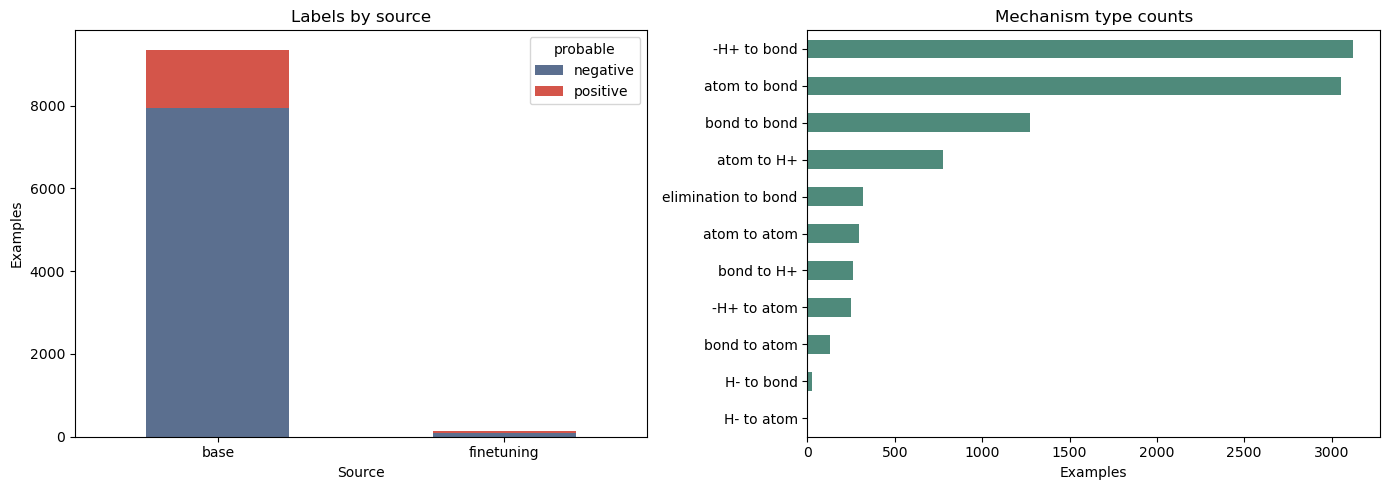

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pd.crosstab(records_df['source'], records_df['probable']).rename(columns={0: 'negative', 1: 'positive'}).plot(
    kind='bar', stacked=True, ax=axes[0], color=['#5b6f8f', '#d4554a']
)
axes[0].set_title('Labels by source')
axes[0].set_xlabel('Source')
axes[0].set_ylabel('Examples')
axes[0].tick_params(axis='x', rotation=0)

mechanism_counts = records_df['mechanism_type_name'].value_counts().sort_values()
mechanism_counts.plot(kind='barh', ax=axes[1], color='#4f8a7b')
axes[1].set_title('Mechanism type counts')
axes[1].set_xlabel('Examples')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


In [16]:
section_totals = (
    feature_summary.groupby('section')['observed_count']
    .sum()
    .reindex([section['section'] for section in build_section_layout()])
)

plt.figure(figsize=(10, 5))
section_totals.plot(kind='bar', color='#7b6d9c')
plt.title('Feature activations by fingerprint section')
plt.xlabel('Fingerprint section')
plt.ylabel('Total active bits')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


NameError: name 'feature_summary' is not defined